### Thư viện tham khảo WhisperX: https://github.com/m-bain/whisperX

To reduce GPU memory requirements, try any of the following (2. & 3. can affect quality):

1. Reduce batch size, e.g. --batch_size 4
2. Use a smaller ASR model --model base
3. Use lighter compute type --compute_type int8

In [12]:
from IPython.display import HTML
import base64

In [13]:
import torch

print("torch:", torch.__version__)
print("cuda:", torch.version.cuda)
print("available:", torch.cuda.is_available())

torch: 2.8.0+cu128
cuda: 12.8
available: True


In [14]:
import os
import warnings

# Tắt cảnh báo symlink của huggingface
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

# Tắt cảnh báo torchcodec và pyannote
warnings.filterwarnings("ignore", message=".*torchcodec.*")
warnings.filterwarnings("ignore", module="pyannote")

In [15]:
!ffmpeg -version

ffmpeg version N-117688-gd6b2d08fc7-20241102 Copyright (c) 2000-2024 the FFmpeg developers
built with gcc 14.2.0 (crosstool-NG 1.26.0.120_4d36f27)
configuration: --prefix=/ffbuild/prefix --pkg-config-flags=--static --pkg-config=pkg-config --cross-prefix=x86_64-w64-mingw32- --arch=x86_64 --target-os=mingw32 --enable-gpl --enable-version3 --disable-debug --disable-w32threads --enable-pthreads --enable-iconv --enable-zlib --enable-libfreetype --enable-libfribidi --enable-gmp --enable-libxml2 --enable-lzma --enable-fontconfig --enable-libharfbuzz --enable-libvorbis --enable-opencl --disable-libpulse --enable-libvmaf --disable-libxcb --disable-xlib --enable-amf --enable-libaom --enable-libaribb24 --enable-avisynth --enable-chromaprint --enable-libdav1d --enable-libdavs2 --enable-libdvdread --enable-libdvdnav --disable-libfdk-aac --enable-ffnvcodec --enable-cuda-llvm --enable-frei0r --enable-libgme --enable-libkvazaar --enable-libaribcaption --enable-libass --enable-libbluray --enable-libjxl

In [16]:
import whisperx

device = "cuda"
# compute_type = "float16"
compute_type = "int8"
batch_size = 8

model = whisperx.load_model("large-v3", device=device, compute_type=compute_type)

2026-09-20 13:57:19 - whisperx.asr - INFO - No language specified, language will be detected for each audio file (increases inference time)
2026-09-20 13:57:19 - whisperx.vads.pyannote - INFO - Performing voice activity detection using Pyannote...


Lightning automatically upgraded your loaded checkpoint from v1.5.4 to v2.6.6. To apply the upgrade to your files permanently, run `python -m lightning.pytorch.utilities.upgrade_checkpoint d:\SelfLearning\EchoChunk\server\.venv\Lib\site-packages\whisperx\assets\pytorch_model.bin`


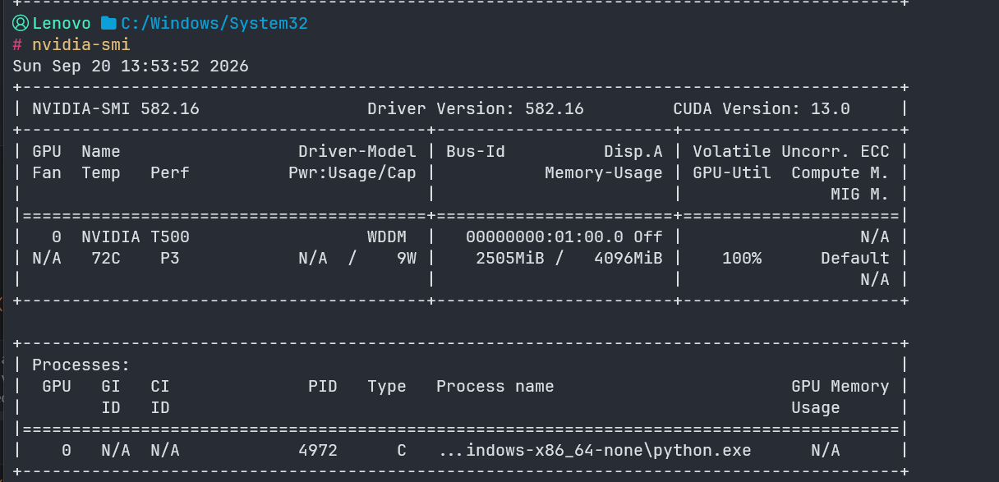

In [6]:
audio = whisperx.load_audio("english.mp3")

result = model.transcribe(audio, batch_size)

2026-09-20 13:53:52 - whisperx.asr - INFO - Detected language: en (1.00) in first 30s of audio


In [7]:
print(result["language"])

en


In [8]:
result["segments"]

[{'text': " So a Vietnamese girl reached out to me because she wanted me to test her English speaking and help her figure out what kind of classes were actually suitable for her. And do you know what I told her? So I told her that I didn't think she needed a speaking class right now. I do have speaking classes, but it doesn't mean that I'm going to sell them at all costs. This girl is currently leaving and working in China. But before that, she worked for an international company in Vietnam for about four years.",
  'start': 0.031,
  'end': 29.562,
  'avg_logprob': -0.022189670535563318},
 {'text': ' And during that time, she was speaking English at work pretty much. And she told me her English used to be pretty good and fluent. And then she felt burned out and moved to China and then started working there. And for the last two years, she has been using Chinese her entire time. And because she was speaking Chinese so much, she started to feel like her English was getting worse.',
  'st

### Xác định mốc thời gian nói từng word

In [9]:
model_a, metadata = whisperx.load_align_model(
    language_code=result["language"], device=device
)

result_aligned = whisperx.align(result["segments"], model_a, metadata, audio, device)

In [10]:
result_aligned["segments"][0]["words"]

[{'word': 'So',
  'start': np.float64(0.271),
  'end': np.float64(0.571),
  'score': np.float64(0.985)},
 {'word': 'a',
  'start': np.float64(0.591),
  'end': np.float64(0.611),
  'score': np.float64(0.001)},
 {'word': 'Vietnamese',
  'start': np.float64(0.831),
  'end': np.float64(1.271),
  'score': np.float64(0.708)},
 {'word': 'girl',
  'start': np.float64(1.311),
  'end': np.float64(1.492),
  'score': np.float64(0.889)},
 {'word': 'reached',
  'start': np.float64(1.552),
  'end': np.float64(1.812),
  'score': np.float64(0.448)},
 {'word': 'out',
  'start': np.float64(1.892),
  'end': np.float64(2.012),
  'score': np.float64(0.745)},
 {'word': 'to',
  'start': np.float64(2.032),
  'end': np.float64(2.272),
  'score': np.float64(0.731)},
 {'word': 'me',
  'start': np.float64(2.292),
  'end': np.float64(2.332),
  'score': np.float64(0.0)},
 {'word': 'because',
  'start': np.float64(2.412),
  'end': np.float64(2.612),
  'score': np.float64(0.892)},
 {'word': 'she',
  'start': np.float6

In [11]:
# 1. Đường dẫn tới file âm thanh
audio_file = "./english.mp3"

with open(audio_file, "rb") as f:
    audio_base64 = base64.b64encode(f.read()).decode("utf-8")

# 2. Thu thập và ép kiểu float chuẩn (tránh np.float64)
words_data = []
for segment in result_aligned["segments"]:
    if "words" in segment:
        for w in segment["words"]:
            words_data.append(
                {
                    "word": w["word"],
                    "start": float(w["start"]) if w.get("start") is not None else None,
                    "end": float(w["end"]) if w.get("end") is not None else None,
                }
            )

# 3. Nội suy các từ bị thiếu mốc thời gian
for i in range(len(words_data)):
    if words_data[i]["start"] is None:
        prev_end = 0.0
        for j in range(i - 1, -1, -1):
            if words_data[j]["end"] is not None:
                prev_end = words_data[j]["end"]
                break

        next_start = prev_end + 0.4
        for j in range(i + 1, len(words_data)):
            if words_data[j]["start"] is not None:
                next_start = words_data[j]["start"]
                break

        words_data[i]["start"] = prev_end
        words_data[i]["end"] = next_start

# 4. Tạo giao diện HTML / CSS / JS
html_content = f"""
<div id="whisper-player-wrap" style="font-family: 'Inter', -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; max-width: 800px; margin: 20px auto; padding: 30px; border-radius: 20px; background: #ffffff; box-shadow: 0 10px 30px rgba(0,0,0,0.07);">
    <h3 style="color: #1e1e24; text-align: center; margin-bottom: 20px; font-weight: 700; letter-spacing: -0.5px;">Interactive Transcript</h3>
    
    <div style="text-align: center; margin-bottom: 25px;">
        <audio id="whisper-audio" controls style="width: 100%; max-width: 600px; border-radius: 30px;">
            <source src="data:audio/mp3;base64,{audio_base64}" type="audio/mp3">
            Your browser does not support the audio element.
        </audio>
    </div>
    
    <div id="whisper-transcript" style="line-height: 2.2; font-size: 20px; max-height: 350px; overflow-y: auto; padding: 25px; border-radius: 16px; background: #f8fafc; scroll-behavior: smooth;">
"""

for idx, item in enumerate(words_data):
    word_clean = str(item["word"]).replace('"', "&quot;")
    html_content += f'<span class="karaoke-word" id="word-{idx}" data-start="{item["start"]:.3f}" data-end="{item["end"]:.3f}">{word_clean}</span> '

html_content += """
    </div>
</div>

<style>
    .karaoke-word {
        display: inline-block;
        color: #94a3b8; /* Chữ xám mờ khi chưa đọc tới */
        transition: color 0.15s ease, transform 0.15s ease;
        cursor: pointer;
        border-radius: 4px;
        padding: 0 2px;
    }
    .karaoke-word:hover {
        background: #e2e8f0;
    }
    /* Đang nói tới từ này (Highlight Karaoke) */
    .karaoke-word.highlight {
        color: #2563eb !important;
        font-weight: 700;
        transform: scale(1.1);
        text-shadow: 0 0 12px rgba(37, 99, 235, 0.3);
    }
    /* Đã nói qua */
    .karaoke-word.passed {
        color: #1e293b !important;
    }
</style>

<script>
(() => {
    const audio = document.getElementById('whisper-audio');
    const container = document.getElementById('whisper-transcript');
    const wordSpans = Array.from(container.querySelectorAll('.karaoke-word'));
    
    if (!audio || wordSpans.length === 0) return;

    // Cache lại start và end dạng số để tăng hiệu năng tối đa
    const words = wordSpans.map(el => ({
        el: el,
        start: parseFloat(el.getAttribute('data-start')),
        end: parseFloat(el.getAttribute('data-end'))
    }));

    let lastActiveEl = null;

    audio.addEventListener('timeupdate', () => {
        const currentTime = audio.currentTime;
        
        for (let i = 0; i < words.length; i++) {
            const w = words[i];
            
            if (currentTime >= w.start && currentTime <= w.end) {
                if (lastActiveEl !== w.el) {
                    if (lastActiveEl) lastActiveEl.classList.remove('highlight');
                    w.el.classList.add('highlight');
                    w.el.classList.remove('passed');
                    lastActiveEl = w.el;
                    
                    // Cuộn từ đang đọc vào giữa khung
                    w.el.scrollIntoView({ behavior: 'smooth', block: 'center' });
                }
            } else if (currentTime > w.end) {
                w.el.classList.remove('highlight');
                w.el.classList.add('passed');
            } else {
                w.el.classList.remove('highlight');
                w.el.classList.remove('passed');
            }
        }
    });

    // Click vào từ để nhảy audio đến từ đó
    words.forEach(w => {
        w.el.addEventListener('click', () => {
            audio.currentTime = w.start;
            audio.play();
        });
    });
})();
</script>
"""

HTML(html_content)

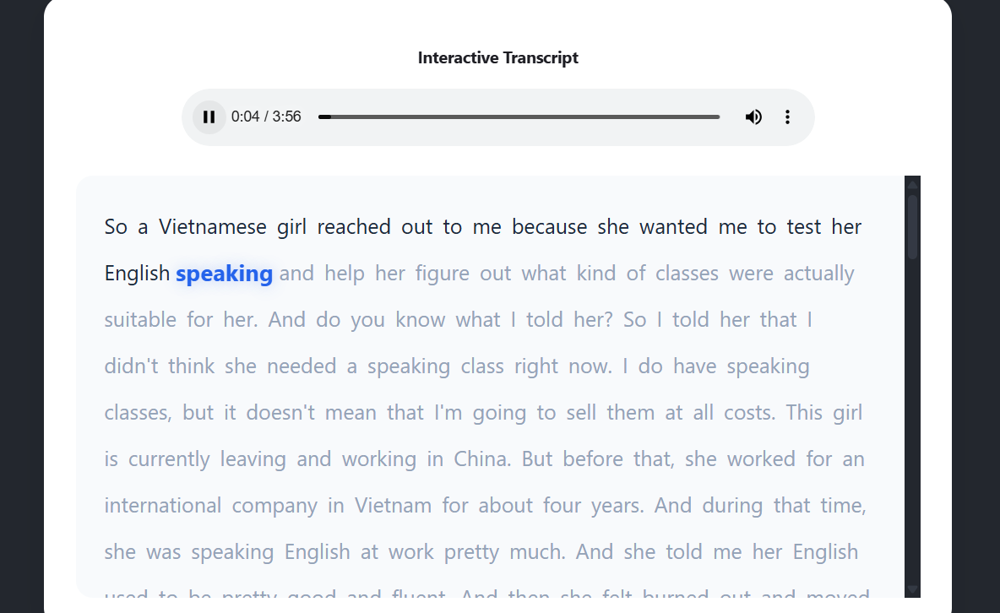